# Gold price regression — chronological evaluation

This is an educational comparison of Gradient Boosting, AdaBoost and Ridge against a previous-observation baseline. The source financial dataset has a `gold close` column (not a `GLD` ETF column). By default this notebook runs on **synthetic demonstration data**. Download the real dataset yourself to `data/raw/financial_regression.csv` for the full experiment. The raw dataset is deliberately not redistributed.

The experiment evaluates rolling **one-step-ahead** predictions using observed previous prices; it is **not** a multi-day forecast or trading strategy.

In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from src.regression import prepare_series, evaluate

real_path = ROOT / "data/raw/financial_regression.csv"
source = real_path if real_path.exists() else ROOT / "data/sample/synthetic_gold.csv"
print("Source:", source.relative_to(ROOT))
raw = pd.read_csv(source)
print("Shape:", raw.shape)
print("Available columns:", list(raw.columns[:12]))

Source: data\sample\synthetic_gold.csv
Shape: (260, 2)
Available columns: ['date', 'gold close']


In [2]:
data = prepare_series(raw, "date", "gold close")
print("Prepared observations:", len(data))
print("Period:", data["date"].min().date(), "to", data["date"].max().date())
results, predictions, test, selected = evaluate(data, "gold close")
print("Best ML model selected using training-only time-series CV:", selected)
display(results.round(3))

Prepared observations: 253
Period: 2023-01-11 to 2023-12-29
Best ML model selected using training-only time-series CV: AdaBoost


,model,cv_mae,test_mae,test_rmse,test_r2
0,Gradient Boosting,1.084,1.013,1.318,0.769
1,AdaBoost,1.048,0.961,1.229,0.800
2,Ridge,1.299,1.029,1.312,0.771
3,Previous observation,NaN,1.045,1.336,0.763


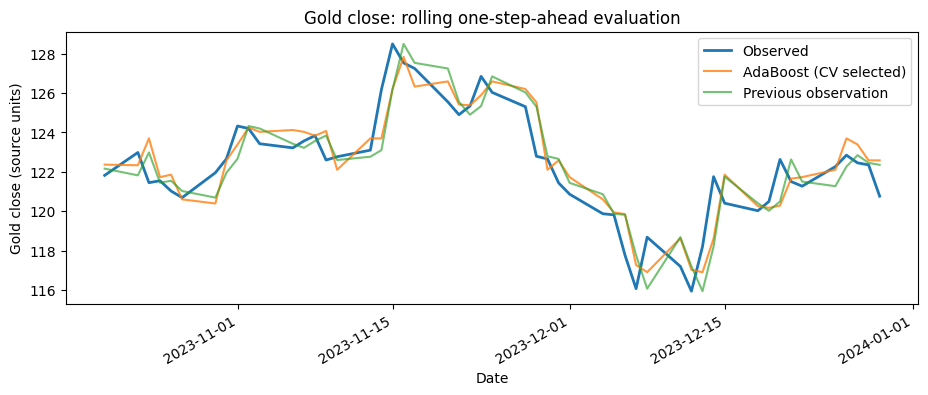

In [3]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(test["date"], test["gold close"], label="Observed", linewidth=2)
ax.plot(test["date"], predictions[selected], label=f"{selected} (CV selected)", alpha=.8)
ax.plot(test["date"], predictions["Previous observation"], label="Previous observation", alpha=.65)
ax.set(title="Gold close: rolling one-step-ahead evaluation", xlabel="Date", ylabel="Gold close (source units)")
ax.legend()
fig.autofmt_xdate()
plt.show()

## Interpretation and limitations

- The test period is strictly later than the training period. Hyperparameter choices are illustrative, not extensively tuned.
- The selected ML model is chosen by time-series cross-validation **within training data**; the holdout is used for final reporting only.
- Lagged test features use observed earlier prices, which assumes observations arrive sequentially. This is not a recursive forecast for the entire holdout.
- The previous-observation baseline is essential: high R² alone does not establish useful predictive skill.
- The synthetic demonstration dataset is not evidence of real-world performance; rerun with the original CSV to obtain real-data metrics.